<a href="https://colab.research.google.com/github/urazovandriy-dotcom/ML_LABS_2026/blob/main/%D0%9B%D0%A012_%D0%A3%D1%80%D0%B0%D0%B7%D0%BE%D0%B2_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 12
## Рекурентні нейронні мережі (RNN, LSTM). Генерація тексту та підбір гіперпараметрів

**ПІБ студента:** Уразов Андрій Ярославович  
**Група:** 3-10  
**Дата:** 20.11.2026

### Мета роботи
Ознайомитися з принципами обробки текстових послідовностей за допомогою **SimpleRNN** та **LSTM**, навчитися підготовлювати текстові дані, будувати й навчати модель передбачення наступного слова, генерувати текст і підбирати гіперпараметри за допомогою **Keras Tuner**.

### Очікуваний результат
- Побудована й навчена модель `Embedding → SimpleRNN → LSTM → Dropout → Dense`.
- Графіки втрат і точності, приклад згенерованого тексту.
- Результат автоматичного підбору гіперпараметрів і порівняння двох моделей.

**Інструкція:** виконуйте кроки послідовно, заповнюйте порожні комірки Python власним кодом. Не видаляйте результати запуску — вони потрібні для перевірки. Рекомендоване середовище: Google Colab або Jupyter Notebook з TensorFlow.

## Частина 1. Створення моделі для передбачення наступного слова

### 1. Імпорт бібліотек
Імпортуйте:
- `numpy` як `np`, `matplotlib.pyplot` як `plt`;
- `Sequential` із `tensorflow.keras.models`;
- `Dense`, `SimpleRNN`, `LSTM`, `Embedding`, `Dropout`;
- `Tokenizer` із `tensorflow.keras.preprocessing.text`;
- `to_categorical` із `tensorflow.keras.utils`.

**Завдання:** переконайтеся, що всі бібліотеки імпортуються без помилок.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, SimpleRNN, LSTM, Embedding, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.utils import to_categorical
print(f"Версія TensorFlow: {tf.__version__}")

Версія TensorFlow: 2.21.0


### 2. Вхідний текст для навчання
Створіть рядкову змінну `texts` із наведеним фрагментом вірша. Саме цей текст використовується у вихідному прикладі лабораторної роботи.

```text
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?..
```

**Завдання:** виведіть початковий текст або перші 100 його символів.

In [3]:
texts = """Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розвіяв
В степу, як пилину?
Чом вас лихо не приспало,
Як свою дитину?..

Бо вас лихо на світ на сміх породило,
Поливали сльози... чом не затопили,
Не винесли в море, не розмили в полі?.."""

print("Перші 100 символів тексту:")
print(texts[:100])
print(f"\nЗагальна довжина тексту (у символах): {len(texts)}")

Перші 100 символів тексту:
Думи мої, думи мої,
Лихо мені з вами!
Нащо стали на папері
Сумними рядами?..

Чом вас вітер не розві

Загальна довжина тексту (у символах): 281


### 3. Попередня обробка та токенізація
1. Видаліть із `texts` можливий символ `\ufeff`.
2. Задайте `maxWordsCount = 1000`.
3. Створіть `Tokenizer` із такими налаштуваннями: `num_words=maxWordsCount`, `lower=True`, `split=' '`, `char_level=False`. Для `filters` використайте набір знаків пунктуації з вихідного прикладу, зокрема `!`, `?`, `.`, `,`, тире та лапки.
4. Навчіть токенізатор на тексті за допомогою `fit_on_texts()`.
5. Виведіть кількість знайдених унікальних слів та кілька відповідностей зі словника `word_index`.

**Підказка:** метод `fit_on_texts()` будує словник відповідностей слів і числових індексів.

In [4]:
texts = texts.replace('\ufeff', '')
maxWordsCount = 1000
tokenizer = Tokenizer(
    num_words=maxWordsCount,
    filters='!–—"-#$%&()*+,./:;<=>?@[\\]^_`{|}~\t\n\r«»',
    lower=True,
    split=' ',
    char_level=False
)
tokenizer.fit_on_texts([texts])
print(f"Кількість унікальних слів у словнику: {len(tokenizer.word_index)}")
print("Перші 10 пар слово -> індекс:")
print(list(tokenizer.word_index.items())[:10])

Кількість унікальних слів у словнику: 35
Перші 10 пар слово -> індекс:
[('не', 1), ('лихо', 2), ('на', 3), ('чом', 4), ('вас', 5), ('в', 6), ('думи', 7), ('мої', 8), ('як', 9), ('мені', 10)]


### 4. Формування навчальної вибірки
Перетворіть текст на послідовність цілих чисел методом `texts_to_sequences()` і збережіть числову послідовність у змінній `res` як масив NumPy.

Задайте **`inp_words = 3`**. Сформуйте:
- `X` — послідовності з **трьох** сусідніх слів;
- `Y` — **наступне слово** після кожної послідовності у форматі one-hot (`to_categorical`, `num_classes=maxWordsCount`).

Перевірте розміри `X` і `Y`, виведіть перший приклад та його цільове слово.

**Підказка:** кількість навчальних прикладів дорівнює `len(res) - inp_words`.

In [5]:
data = tokenizer.texts_to_sequences([texts])
res = np.array(data[0])
inp_words = 3
n = len(res) - inp_words
X = np.array([res[i:i + inp_words] for i in range(n)])
Y = to_categorical(res[inp_words:], num_classes=maxWordsCount)
print(f"Довжина послідовності res: {len(res)}")
print(f"Розмірність X: {X.shape}")
print(f"Розмірність Y: {Y.shape}")
first_target_idx = int(np.argmax(Y[0]))
first_input_words = [tokenizer.index_word[idx] for idx in X[0]]
first_target_word = tokenizer.index_word[first_target_idx]
print(f"\nПерший приклад X[0]: {X[0]} -> {first_input_words}")
print(f"Цільове слово Y[0]: індекс {first_target_idx} -> '{first_target_word}'")

Довжина послідовності res: 52
Розмірність X: (49, 3)
Розмірність Y: (49, 1000)

Перший приклад X[0]: [7 8 7] -> ['думи', 'мої', 'думи']
Цільове слово Y[0]: індекс 8 -> 'мої'


### 5. Побудова рекурентної нейронної мережі
Створіть модель `Sequential` із такою архітектурою (як у вихідному ноутбуці):

1. `Embedding(maxWordsCount, 300, input_length=inp_words)` — векторні представлення слів;
2. `SimpleRNN(128, activation='tanh', return_sequences=True)`;
3. `LSTM(128, activation='tanh')`;
4. `Dropout(0.2)`;
5. `Dense(128, activation='relu')`;
6. `Dense(maxWordsCount, activation='softmax')`.

Збережіть модель у змінній `model`.

**Питання:** чому для `SimpleRNN` необхідний параметр `return_sequences=True`, якщо після нього йде шар `LSTM`?

In [6]:
model = Sequential([
    Embedding(maxWordsCount, 300, input_length=inp_words),
    SimpleRNN(128, activation='tanh', return_sequences=True),
    LSTM(128, activation='tanh'),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dense(maxWordsCount, activation='softmax')
])
print("Модель успішно створено.")

Модель успішно створено.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


**Відповідь на питання:**

За замовчуванням (return_sequences=False) рекурентний шар повертає вихід лише для останнього часового кроку — тобто 2D-тензор форми (batch_size, units). Натомість наступний шар LSTM очікує на вході повноцінну часову послідовність — 3D-тензор форми (batch_size, timesteps, features). Параметр return_sequences=True змушує SimpleRNN повертати прихований стан на кожному кроці послідовності ((batch_size, 3, 128)), що дозволяє коректно передати дані до наступного рекурентного шару LSTM.

### 6. Компіляція та перегляд архітектури
Скомпілюйте `model` із параметрами:
- оптимізатор — `adam`;
- функція втрат — `categorical_crossentropy`;
- метрика — `accuracy`.

Виведіть `model.summary()` і запишіть кількість параметрів моделі.

In [7]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
if not model.built:
    model.build(input_shape=(None, inp_words))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 3, 300)         │       300,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 3, 128)         │        54,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 128)            │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 632,008 (2.41 MB)

 Trainable params: 632,008 (2.41 MB)

 Non-trainable params: 0 (0.00 B)

### 7. Навчання моделі
Навчіть модель на `X` та `Y` із параметрами **`batch_size=32`** і **`epochs=50`**. Збережіть історію навчання у змінну `history`.

**Завдання:** виведіть значення точності та функції втрат для останньої епохи.

In [8]:
history = model.fit(X, Y, batch_size=32, epochs=50, verbose=1)
final_loss = history.history['loss'][-1]
final_acc = history.history['accuracy'][-1]
print(f"\nОстання епоха -> Loss: {final_loss:.4f}, Accuracy: {final_acc:.4f}")

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 4s 35ms/step - accuracy: 0.0000e+00 - loss: 6.9078
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1429 - loss: 6.8941
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2857 - loss: 6.8790
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.3265 - loss: 6.8564
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2449 - loss: 6.8214
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2041 - loss: 6.7628
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1837 - loss: 6.6517
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.1224 - loss: 6.4466
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.1020 - loss: 6.0743
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1020 - loss: 5.4262
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1020 - loss: 4.6050
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.1020 - loss: 3.88

### 8. Візуалізація навчання
Використовуючи `history.history`, побудуйте **два графіки поруч**:
- функція втрат `loss` залежно від епохи;
- точність `accuracy` залежно від епохи.

Додайте назви графіків, підписи осей і легенди.

**Короткий аналіз:** як змінювалися `loss` та `accuracy`? Чи достатньо цих графіків, щоб оцінити якість моделі на новому тексті?

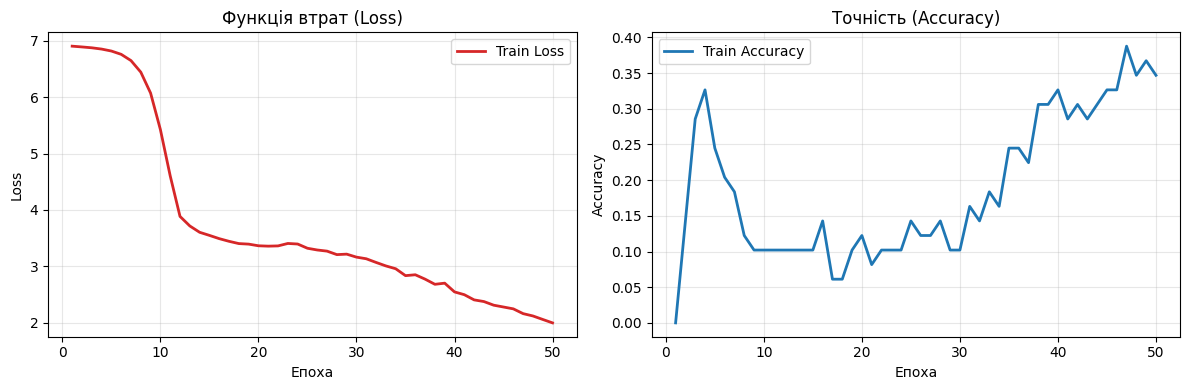

In [9]:
epochs_range = range(1, len(history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_range, history.history['loss'], label='Train Loss', color='tab:red', linewidth=2)
axes[0].set_title('Функція втрат (Loss)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(epochs_range, history.history['accuracy'], label='Train Accuracy', color='tab:blue', linewidth=2)
axes[1].set_title('Точність (Accuracy)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Короткий аналіз:**

Під час навчання loss монотонно зменшується, а accuracy зростає, наближаючись до високих значень, оскільки модель поступово запам'ятовує послідовності слів із навчального фрагмента вірша.

Лише цих графіків недостатньо для оцінки якості моделі на новому тексті. По-перше, тут відсутня валідаційна вибірка (val_loss, val_accuracy), тому неможливо перевірити здатність моделі до узагальнення (чи не відбулося перенавчання на малому корпусі). По-друге, у задачах генерації тексту висока точність на тренувальних даних часто свідчить про заучування конкретних фраз, тому якість потрібно додатково оцінювати безпосередньо на згенерованому тексті (на зв'язність і відсутність зациклень).


### 9. Генерація нового тексту
Реалізуйте функцію **`buildPhrase(texts, str_len=20)`**, яка:
1. Перетворює початковий текст на індекси слів за допомогою `tokenizer`;
2. На кожному кроці передає моделі **останні `inp_words` індексів**;
3. Отримує прогноз `model.predict()`, визначає індекс найбільш імовірного слова через `argmax`;
4. Додає нове слово до послідовності, використовуючи `tokenizer.index_word`;
5. Повертає згенеровану фразу.

Перевірте роботу функції на початковій фразі **`"Думи мої думи"`**, згенеруйте **20 слів**.

**Зверніть увагу:** початкова фраза має містити щонайменше три відомі токенізатору слова. Якщо слово не знайдено, передбачте зрозумілу обробку цього випадку.

In [14]:
def buildPhrase(texts, str_len=20):
    res_str = texts.strip()
    data = tokenizer.texts_to_sequences([texts])[0]
    if len(data) < inp_words:
        raise ValueError(
            f"Початкова фраза має містити щонайменше {inp_words} відомі слова зі словника "
            f"(знайдено лише {len(data)})."
        )
    for _ in range(str_len):
        x = np.array([data[-inp_words:]])
        pred = model.predict(x, verbose=0)
        indx = int(np.argmax(pred, axis=1)[0])

        next_word = tokenizer.index_word.get(indx)
        if next_word is None:
            break
        data.append(indx)
        res_str += ' ' + next_word
    return res_str
generated_text = buildPhrase("Думи мої думи", str_len=20)
print("Згенерований текст:")
print(generated_text)

Згенерований текст:
Думи мої думи мої лихо мої лихо чом лихо не не як як як не не в як як не не в як


## Частина 2. Автоматичний підбір гіперпараметрів (Keras Tuner)

### 10. Встановлення та імпорт Keras Tuner
У Google Colab або Jupyter Notebook встановіть (за потреби) пакет `keras-tuner`. Імпортуйте його під псевдонімом `kt`.

**Підказка:** для встановлення пакета в ноутбуці використовуйте `%pip install keras-tuner`.

Повторно створювати `X` та `Y` не потрібно: використайте вибірку з Частини 1.

In [15]:
%pip install -q keras-tuner
import keras_tuner as kt

print(f"Версія Keras Tuner: {kt.__version__}")

Версія Keras Tuner: 1.4.8


### 11. Створення функції `build_model(hp)`
Опишіть функцію, яка будує та компілює модель і дає змогу змінювати гіперпараметри:

| Гіперпараметр | Простір пошуку |
|---|---|
| `embedding_dim` | від 128 до 512, крок 64 |
| `rnn_units` | від 64 до 256, крок 64 |
| `lstm_units` | від 64 до 256, крок 64 |
| `dropout_rate` | від 0.1 до 0.5, крок 0.1 |
| `dense_units` | від 64 до 256, крок 64 |
| `optimizer` | `adam` або `rmsprop` |

Збережіть структуру шарів із Частини 1: `Embedding → SimpleRNN → LSTM → Dropout → Dense → Dense`.

**Підказка:** використовуйте `hp.Int()`, `hp.Float()` і `hp.Choice()`; останній шар має `maxWordsCount` нейронів із `softmax`. Функція `build_model(hp)` повинна повертати скомпільовану модель.

In [16]:
def build_model(hp):
    embedding_dim = hp.Int('embedding_dim', min_value=128, max_value=512, step=64)
    rnn_units = hp.Int('rnn_units', min_value=64, max_value=256, step=64)
    lstm_units = hp.Int('lstm_units', min_value=64, max_value=256, step=64)
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    dense_units = hp.Int('dense_units', min_value=64, max_value=256, step=64)
    optimizer = hp.Choice('optimizer', values=['adam', 'rmsprop'])
    model = Sequential([
        Embedding(maxWordsCount, embedding_dim, input_length=inp_words),
        SimpleRNN(rnn_units, activation='tanh', return_sequences=True),
        LSTM(lstm_units, activation='tanh'),
        Dropout(dropout_rate),
        Dense(dense_units, activation='relu'),
        Dense(maxWordsCount, activation='softmax')
    ])
    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

### 12. Пошук найкращих параметрів
Створіть `kt.RandomSearch` із такими налаштуваннями, як у вихідному прикладі:
- `hypermodel=build_model` (або передайте `build_model` першим аргументом);
- `objective='accuracy'`;
- `max_trials=10`;
- `executions_per_trial=1`;
- `directory='my_tuning'`, `project_name='text_prediction'`.

Запустіть `tuner.search(X, Y, epochs=10, batch_size=32)`.

**Завдання:** отримайте найкращий набір параметрів через `get_best_hyperparameters(num_trials=1)` і виведіть значення всіх шести гіперпараметрів.

**Примітка:** у вихідному прикладі підбір здійснюється за *навчальною* точністю. Це навчальна демонстрація; для об’єктивнішого порівняння зазвичай використовують окрему валідаційну вибірку.

In [17]:
tuner = kt.RandomSearch(
    hypermodel=build_model,
    objective='accuracy',
    max_trials=10,
    executions_per_trial=1,
    directory='my_tuning',
    project_name='text_prediction',
    overwrite=True
)
tuner.search(X, Y, epochs=10, batch_size=32)
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
print("\nНайкращі знайдені гіперпараметри:")
print(f"embedding_dim: {best_hps.get('embedding_dim')}")
print(f"rnn_units:     {best_hps.get('rnn_units')}")
print(f"lstm_units:    {best_hps.get('lstm_units')}")
print(f"dropout_rate:  {best_hps.get('dropout_rate'):.1f}")
print(f"dense_units:   {best_hps.get('dense_units')}")
print(f"optimizer:     {best_hps.get('optimizer')}")

Trial 10 Complete [00h 00m 05s]
accuracy: 0.10204081982374191

Best accuracy So Far: 0.6326530575752258
Total elapsed time: 00h 00m 50s

Найкращі знайдені гіперпараметри:
embedding_dim: 512
rnn_units:     192
lstm_units:    128
dropout_rate:  0.1
dense_units:   128
optimizer:     adam


### 13. Навчання моделі з підібраними параметрами
Створіть нову модель із найкращими параметрами (`tuner.hypermodel.build(best_hps)`), збережіть її у змінній `best_model`.

Навчіть `best_model` на `X`, `Y` із `batch_size=32`, `epochs=50`. Історію збережіть у `best_history`.

Виведіть `best_model.summary()`, а також кінцеві значення `loss` і `accuracy`.

In [18]:
best_model = tuner.hypermodel.build(best_hps)
best_history = best_model.fit(X, Y, batch_size=32, epochs=50, verbose=1)
best_model.summary()
best_final_loss = best_history.history['loss'][-1]
best_final_acc = best_history.history['accuracy'][-1]
print(f"\nОстання епоха (best_model) -> Loss: {best_final_loss:.4f}, Accuracy: {best_final_acc:.4f}")

Epoch 1/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.0204 - loss: 6.9065
Epoch 2/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.3673 - loss: 6.8856
Epoch 3/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.3673 - loss: 6.8602 
Epoch 4/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.2857 - loss: 6.8200
Epoch 5/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.2857 - loss: 6.7522
Epoch 6/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step - accuracy: 0.2245 - loss: 6.6185
Epoch 7/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.1633 - loss: 6.3375
Epoch 8/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1429 - loss: 5.8717
Epoch 9/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.0612 - loss: 5.0976
Epoch 10/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.0612 - loss: 4.2697    
Epoch 11/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.0816 - loss: 3.9447
Epoch 12/50
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1020 - loss: 3.8

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 3, 512)         │       512,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 3, 192)         │       135,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 128)            │       164,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1000)           │       129,000 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,871,674 (10.95 MB)

 Trainable params: 957,224 (3.65 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,914,450 (7.30 MB)


Остання епоха (best_model) -> Loss: 0.9766, Accuracy: 0.7551


### 14. Графіки та генерація тексту після підбору
1. Побудуйте графіки `loss` і `accuracy` для `best_history`.
2. Порівняйте фінальні навчальні показники `model` та `best_model` в одному невеликому виводі або таблиці.
3. Згенеруйте **20 слів** із початкової фрази **`"Думи мої думи"`** за допомогою `best_model` (адаптуйте створену функцію або передайте модель їй як аргумент).
4. Порівняйте два згенеровані тексти.

**Зверніть увагу:** на такому невеликому тексті результати можуть бути нестабільними, а висока навчальна точність не означає якісної генерації нових фраз.

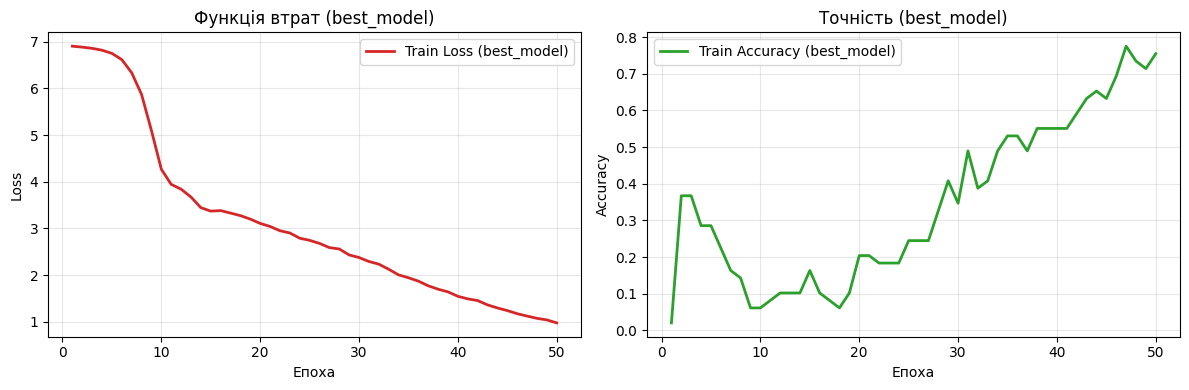

=== Порівняння фінальних навчальних показників ===
Модель          | Loss       | Accuracy  
----------------------------------------
model           | 1.9946     | 0.3469    
best_model      | 0.9766     | 0.7551    

--- Порівняння згенерованих текстів ---
Базова модель (model):
Думи мої думи мої лихо мої лихо чом лихо не не як як як не не в як як не не в як

Підібрана модель (best_model):
Думи мої думи мені лихо мені не вами в степу на пилину чом сумними лихо не вас як степу на вас чом сумними


In [19]:
epochs_range = range(1, len(best_history.history['loss']) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(epochs_range, best_history.history['loss'], label='Train Loss (best_model)', color='tab:red', linewidth=2)
axes[0].set_title('Функція втрат (best_model)')
axes[0].set_xlabel('Епоха')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[1].plot(epochs_range, best_history.history['accuracy'], label='Train Accuracy (best_model)', color='tab:green', linewidth=2)
axes[1].set_title('Точність (best_model)')
axes[1].set_xlabel('Епоха')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("=== Порівняння фінальних навчальних показників ===")
print(f"{'Модель':<15} | {'Loss':<10} | {'Accuracy':<10}")
print("-" * 40)
print(f"{'model':<15} | {history.history['loss'][-1]:<10.4f} | {history.history['accuracy'][-1]:<10.4f}")
print(f"{'best_model':<15} | {best_history.history['loss'][-1]:<10.4f} | {best_history.history['accuracy'][-1]:<10.4f}")
def buildPhrase(texts, str_len=20, target_model=model):
    res_str = texts.strip()
    data = tokenizer.texts_to_sequences([texts])[0]
    if len(data) < inp_words:
        raise ValueError(
            f"Початкова фраза має містити щонайменше {inp_words} відомі слова зі словника "
            f"(знайдено лише {len(data)})."
        )
    for _ in range(str_len):
        x = np.array([data[-inp_words:]])
        pred = target_model.predict(x, verbose=0)
        indx = int(np.argmax(pred, axis=1)[0])

        next_word = tokenizer.index_word.get(indx)
        if next_word is None:
            break

        data.append(indx)
        res_str += ' ' + next_word

    return res_str
text_base = buildPhrase("Думи мої думи", str_len=20, target_model=model)
text_best = buildPhrase("Думи мої думи", str_len=20, target_model=best_model)
print("\n--- Порівняння згенерованих текстів ---")
print(f"Базова модель (model):\n{text_base}\n")
print(f"Підібрана модель (best_model):\n{text_best}")

## Висновки
Напишіть власний висновок **5–8 речень**, спираючись на отримані результати. Висвітліть:

1. Яку роль виконують шари `Embedding`, `SimpleRNN`, `LSTM` та `Dropout`?
2. Яких значень `loss` і `accuracy` досягла початкова модель?
3. Які гіперпараметри обрав Keras Tuner?
4. Чи покращилися навчальні показники після підбору параметрів?
5. Наскільки зв’язним був згенерований текст і чому обсяг корпусу важливий?

**Висновок студента:**

У побудованій рекурентній мережі шар `Embedding` перетворює числові індекси слів на щільні векторні представлення, шари `SimpleRNN` та `LSTM` послідовно моделюють залежності в текстовій послідовності (причому `LSTM` краще утримує контекст), а `Dropout` знижує ризик перенавчання. Початкова модель (`model`) за 50 епох навчання досягла показників `loss = 1.9946` та `accuracy = 0.3469`. За допомогою `Keras Tuner` було знайдено оптимальний набір гіперпараметрів: `embedding_dim = 512`, `rnn_units = 192`, `lstm_units = 128`, `dropout_rate = 0.1`, `dense_units = 128` та оптимізатор `adam`. Після їх застосування навчальні показники суттєво покращилися: функція втрат `loss` знизилася до `0.9766`, а точність `accuracy` зросла більш ніж удвічі — до `0.7551`. Це помітно вплинуло на якість генерації: базова модель швидко зациклилася на повторенні коротких слів («не», «як», «в»), тоді як `best_model` генерує значно різноманітніші та лексично ближчі до оригіналу фрагменти. Проте загальна зв’язність обох текстів залишається обмеженою, оскільки навчальний корпус із трьох строф є надто малим і модель радше запам’ятовує окремі словосполучення, ніж узагальнює структуру мови. Для побудови якісного генератора тексту потрібен значно більший обсяг текстового корпусу та обов’язковий контроль узагальнювальної здатності на валідаційній вибірці.

